# 22 · Integrators and timestep: accuracy, energy drift and stability

In [1]:
import time, mujoco, numpy as np, matplotlib.pyplot as plt

PEND = """<mujoco><option timestep="{dt}" integrator="{integ}"><flag contact="disable" energy="enable"/></option>
<worldbody><body pos="0 0 1"><joint name="h" axis="0 1 0" damping="{damping}"/>
<geom type="capsule" fromto="0 0 0 .5 0 0" size=".02" mass="1"/></body></worldbody></mujoco>"""

def pendulum(dt, integ, damping=0.0):
    m = mujoco.MjModel.from_xml_string(PEND.format(dt=dt, integ=integ, damping=damping))
    return m, mujoco.MjData(m)

def energy_trace(dt, integ, T=10.0):
    m, d = pendulum(dt, integ)
    mujoco.mj_forward(m, d)
    e0, out = d.energy.sum(), []
    while d.time < T:
        mujoco.mj_step(m, d); out.append(d.energy.sum() - e0)
    return np.arange(len(out)) * dt, np.array(out)

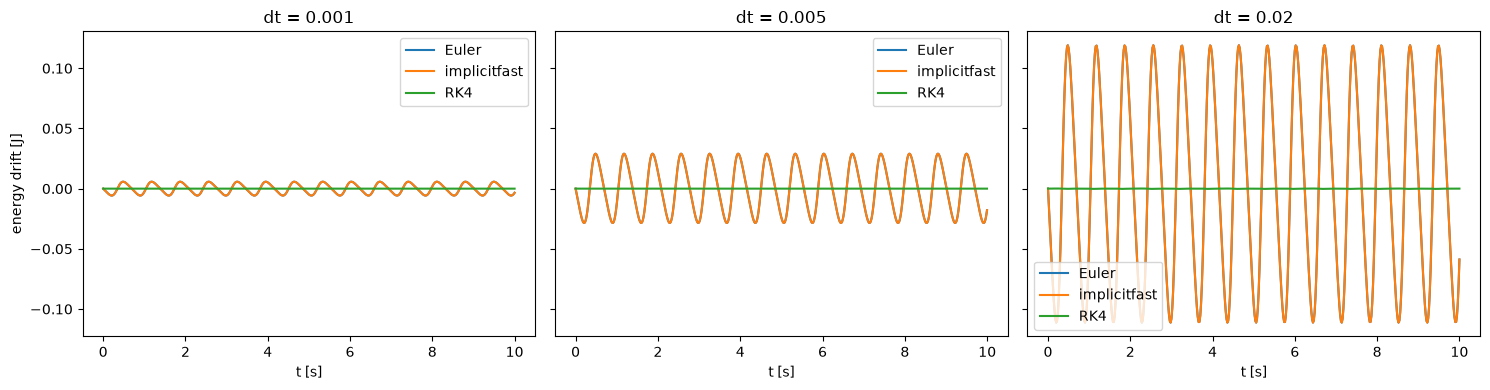

In [2]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
for ax, dt in zip(axes, [0.001, 0.005, 0.02]):
    for integ in ["Euler", "implicitfast", "RK4"]:
        t, e = energy_trace(dt, integ)
        ax.plot(t, e, label=integ)
    ax.set_title(f"dt = {dt}"); ax.set_xlabel("t [s]"); ax.legend()
axes[0].set_ylabel("energy drift [J]"); plt.tight_layout(); plt.show()

In [3]:
rows = []
for integ in ["Euler", "implicitfast", "RK4"]:
    m, d = pendulum(0.002, integ)
    t0 = time.perf_counter(); mujoco.mj_step(m, d, 20000); el = time.perf_counter() - t0
    rows.append((integ, 20000 / el))
for name, sps in rows:
    print(f"{name:13s} {sps:12,.0f} steps/s")

Euler              835,614 steps/s
implicitfast       805,185 steps/s
RK4                263,921 steps/s


In [4]:
STIFF = """<mujoco><option timestep="{dt}" integrator="{integ}"><flag contact="disable" gravity="disable"/></option>
<worldbody><body><joint name="h" axis="0 0 1"/><geom type="capsule" fromto="0 0 0 .5 0 0" size=".02" mass="1"/></body></worldbody>
<actuator>{act}</actuator></mujoco>"""
I = 0.0857
for where, act in [("inside MuJoCo (velocity actuator)", '<velocity joint="h" kv="50"/>'),
                   ("in your Python loop (motor + ctrl = -kv*qvel)", '<motor joint="h" ctrlrange="-1e6 1e6"/>')]:
    for integ in ["Euler", "implicitfast"]:
        for dt in [0.002, 0.005, 0.01]:
            m = mujoco.MjModel.from_xml_string(STIFF.format(dt=dt, integ=integ, act=act)); d = mujoco.MjData(m)
            d.qvel[0] = 1.0
            for _ in range(int(0.5 / dt)):
                if "motor" in act:
                    d.ctrl[0] = -50 * d.qvel[0]
                mujoco.mj_step(m, d)
            ok = np.isfinite(d.qvel[0]) and abs(d.qvel[0]) < 1.0
            print(f"damping {where:45s} {integ:13s} dt={dt:<6} kv*dt/I={50 * dt / I:4.1f}  {'stable' if ok else 'UNSTABLE'}")

damping inside MuJoCo (velocity actuator)             Euler         dt=0.002  kv*dt/I= 1.2  stable
damping inside MuJoCo (velocity actuator)             Euler         dt=0.005  kv*dt/I= 2.9  stable
damping inside MuJoCo (velocity actuator)             Euler         dt=0.01   kv*dt/I= 5.8  stable
damping inside MuJoCo (velocity actuator)             implicitfast  dt=0.002  kv*dt/I= 1.2  stable
damping inside MuJoCo (velocity actuator)             implicitfast  dt=0.005  kv*dt/I= 2.9  stable
damping inside MuJoCo (velocity actuator)             implicitfast  dt=0.01   kv*dt/I= 5.8  stable
damping in your Python loop (motor + ctrl = -kv*qvel) Euler         dt=0.002  kv*dt/I= 1.2  stable
damping in your Python loop (motor + ctrl = -kv*qvel) Euler         dt=0.005  kv*dt/I= 2.9  UNSTABLE
damping in your Python loop (motor + ctrl = -kv*qvel) Euler         dt=0.01   kv*dt/I= 5.8  UNSTABLE
damping in your Python loop (motor + ctrl = -kv*qvel) implicitfast  dt=0.002  kv*dt/I= 1.2  stable
dampin